# Milestone 5: Leakage-Safe Feature Engineering and Dataset Preparation
**Project Title:** An Explainable Data-Driven Framework for Population Health Analytics and Predictive Modeling Using CDC BRFSS 2024  
**Primary Target Outcome:** `_MICHD` (Reported History of Coronary Heart Disease or Myocardial Infarction)  
**Binding Rules Adherence:** Rule 6 (Target lock verification), Rule 8 (Zero global code replacements), Rule 9 (Train-only preprocessing), Rule 10 (Target leakage prevention), Rule 11 (Observational task boundaries), Rule 12 (Complex survey weighting).

---

### Notebook Objectives:
1. **Recompute and Verify Target Outcome (`_MICHD`):** Confirm exact response codes and establish the $N = 452,464$ eligible surveillance cohort.
2. **Enforce Leakage Controls:** Audit all 61 candidate variables and strictly exclude constituent variables (`CVDINFR4`, `CVDCRHD4`).
3. **Survey Metadata Isolation:** Retain complex design variables (`_LLCPWT`, `_STSTR`, `_PSU`, `_STATE`) strictly in metadata for audit and evaluation, never as predictive inputs.
4. **Feature Engineering & Codebook Recoding:** Clean continuous variables (`PHYSHLTH_DAYS`, `MENTHLTH_DAYS`, `BMI_NUMERIC`) and preserve categorical response codes.
5. **Stratified Disjoint Partitioning:** Partition cohort into 70% Train, 15% Validation, and 15% Test splits with fixed random seed (42).
6. **Leakage-Safe Preprocessing Pipeline:** Build and fit scikit-learn `ColumnTransformer` strictly on the training partition.
7. **Verification & Serialization:** Validate artifact integrity in `data/processed/` and export summary audit tables.

In [1]:
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Visual configuration
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 150

# Project path configuration
PROJECT_ROOT = Path("..").resolve()
sys.path.append(str(PROJECT_ROOT))

from src.features import feature_config
from src.features.build_features import (
    load_interim_data,
    filter_eligible_cohort,
    engineer_features,
    partition_data,
    build_preprocessor_pipeline,
    generate_inclusion_exclusion_audit,
    generate_partition_summary
)

DATA_PATH = PROJECT_ROOT / "data" / "interim" / "brfss_2024_selected.csv.gz"
DICT_PATH = PROJECT_ROOT / "data" / "interim" / "brfss_2024_dictionary.json"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
MODELS_DIR = PROJECT_ROOT / "models"

print(f"Project root: {PROJECT_ROOT}")
print(f"Target outcome: {feature_config.TARGET_COL} ({feature_config.TARGET_NAME})")

Project root: C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project
Target outcome: _MICHD (Reported History of Coronary Heart Disease or Myocardial Infarction)


## 1. Codebook Target Verification & Eligible Cohort Extraction

According to the official CDC 2024 Codebook (`USCODE24_LLCP_082125.HTML`), the primary target `_MICHD` is defined as:
- `1` = Reported having MI or CHD (`CVDINFR4=1` OR `CVDCRHD4=1`)
- `2` = Did not report having MI or CHD (`CVDINFR4=2` AND `CVDCRHD4=2`)
- `BLANK` (NaN) = Not asked or missing in either question

We verify these figures against the actual interim dataset and isolate eligible records.

In [2]:
raw_df = load_interim_data(DATA_PATH)
cohort_df, excluded_df = filter_eligible_cohort(raw_df)

# Verify target figures
n_pos = int((cohort_df["target"] == 1).sum())
n_neg = int((cohort_df["target"] == 0).sum())
total_valid = len(cohort_df)
weights = cohort_df["_LLCPWT"]
w_pos = weights[cohort_df["target"] == 1].sum()
w_tot = weights.sum()

print("\n--- Target Verification Summary ---")
print(f"Total raw survey respondents:       {len(raw_df):,}")
print(f"Excluded unasked/missing target:    {len(excluded_df):,} ({len(excluded_df)/len(raw_df)*100:.2f}%)")
print(f"Eligible surveillance cohort:       {total_valid:,} ({total_valid/len(raw_df)*100:.2f}%)")
print(f"Valid positive cases (_MICHD=1):    {n_pos:,} ({n_pos/total_valid*100:.2f}% unweighted, {w_pos/w_tot*100:.2f}% weighted)")
print(f"Valid negative cases (_MICHD=2):    {n_neg:,} ({n_neg/total_valid*100:.2f}% unweighted)")
print(f"Class imbalance ratio:              1 : {n_neg/n_pos:.2f}")

# Assert exact match with official audited figures
assert n_pos == 42338, f"Mismatch in positive cases: {n_pos} != 42,338"
assert n_neg == 410126, f"Mismatch in negative cases: {n_neg} != 410,126"
assert len(excluded_df) == 5206, f"Mismatch in excluded cases: {len(excluded_df)} != 5,206"
print("All target verification assertions passed with 100% precision!")

Loading interim data from C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project\data\interim\brfss_2024_selected.csv.gz...


Loaded 457,670 rows x 61 columns.


Eligible Cohort: 452,464 records (98.86% of survey).
  Target Positive (1): 42,338 (9.36% unweighted, 6.80% weighted).
  Target Negative (0): 410,126 (90.64% unweighted).
Excluded Records: 5,206 (1.14% missing target).

--- Target Verification Summary ---
Total raw survey respondents:       457,670
Excluded unasked/missing target:    5,206 (1.14%)
Eligible surveillance cohort:       452,464 (98.86%)
Valid positive cases (_MICHD=1):    42,338 (9.36% unweighted, 6.80% weighted)
Valid negative cases (_MICHD=2):    410,126 (90.64% unweighted)
Class imbalance ratio:              1 : 9.69
All target verification assertions passed with 100% precision!


## 2. Feature Inclusion / Exclusion Audit & Leakage Controls

To prevent target leakage and multi-collinear redundancy, all 61 variables from the interim dictionary are classified into explicit operational roles:
1. **Primary Target (`_MICHD`):** Excluded from feature space.
2. **Mandatory Leakage Exclusions (`CVDINFR4`, `CVDCRHD4`):** Direct mathematical constituents of `_MICHD`. Banned from predictive inputs.
3. **Survey Design Metadata (`_LLCPWT`, `_STSTR`, `_PSU`, `_STATE`):** Preserved for evaluation, calibration, and subgroup audit; excluded from ordinary feature matrix.
4. **Redundant Variables:** Excluded in favor of richer, more granular representations (e.g. `_AGE65YR` excluded in favor of continuous `_AGE80` and 5-year `_AGEG5YR`).
5. **Included Predictors (38 features):** 4 continuous numeric features + 34 categorical risk factors across demographics, behaviors, healthcare access, comorbidities, and functional limitations.

In [3]:
audit_df = generate_inclusion_exclusion_audit(DICT_PATH)
print(f"Audited {len(audit_df)} variables from {DICT_PATH.name}:")
display(audit_df["variable_status"].value_counts().to_frame("Variable Count"))

# Display leakage exclusions
print("\n--- Mandatory Leakage Exclusions ---")
display(audit_df[audit_df["variable_status"] == "Excluded: Direct Target Leakage"][["raw_variable", "category", "transformation_and_leakage_notes"]])

# Save audit table
audit_table_path = TABLES_DIR / "feature_inclusion_exclusion_audit.csv"
audit_df.to_csv(audit_table_path, index=False)
print(f"Saved feature audit table to {audit_table_path}")

Audited 61 variables from brfss_2024_dictionary.json:


,Variable Count
variable_status,
Included: Categorical Predictor,34
Excluded: Redundant / Skip Pattern,16
Preserved: Survey Metadata,4
Source for Engineered Numeric Predictor,4
Excluded: Direct Target Leakage,2
Primary Prediction Target,1



--- Mandatory Leakage Exclusions ---


,raw_variable,category,transformation_and_leakage_notes
28,CVDINFR4,Chronic Conditions,DIRECT TARGET LEAKAGE: CDC defines _MICHD = 1 ...
29,CVDCRHD4,Chronic Conditions,DIRECT TARGET LEAKAGE: CDC defines _MICHD = 1 ...


Saved feature audit table to C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project\results\tables\feature_inclusion_exclusion_audit.csv


## 3. Feature Engineering & Clean Recoding

We engineer clean predictors according to exact codebook rules without global replacements:
- `PHYSHLTH_DAYS`: Map 88 (None) to 0 days; 77/99 to NaN.
- `MENTHLTH_DAYS`: Map 88 (None) to 0 days; 77/99 to NaN.
- `BMI_NUMERIC`: Rescale continuous `_BMI5` by 100.0 (kg/m$^2$).
- `_AGE80`: Preserved as continuous imputed age (18 to 80 years).
- Categorical features: Cast to string representations so Refusal/DK/Missing codes remain distinct levels.

In [4]:
X, y, metadata_df = engineer_features(cohort_df)

print("\n--- Continuous Numeric Features Summary ---")
display(X[feature_config.NUMERIC_FEATURES].describe().round(2))

# Assertions confirming leakage prevention
assert "_MICHD" not in X.columns, "LEAKAGE ERROR: _MICHD found in X!"
assert "CVDINFR4" not in X.columns, "LEAKAGE ERROR: CVDINFR4 found in X!"
assert "CVDCRHD4" not in X.columns, "LEAKAGE ERROR: CVDCRHD4 found in X!"
assert "_LLCPWT" not in X.columns, "DESIGN ERROR: Survey weight found in X!"
print("Leakage controls verified: no target components or survey weights enter feature matrix X.")

Engineered feature matrix X: 452,464 rows x 38 predictors.
  Numeric predictors (4): ['_AGE80', 'PHYSHLTH_DAYS', 'MENTHLTH_DAYS', 'BMI_NUMERIC']
  Categorical predictors (34): 34 features.

--- Continuous Numeric Features Summary ---


,_AGE80,PHYSHLTH_DAYS,MENTHLTH_DAYS,BMI_NUMERIC
count,452464.00,441918.00,444707.00,410281.00
mean,55.02,4.57,4.40,28.55
std,18.12,8.89,8.34,6.58
min,18.00,0.00,0.00,12.00
25%,40.00,0.00,0.00,24.14
50%,58.00,0.00,0.00,27.44
75%,70.00,4.00,5.00,31.75
max,80.00,30.00,30.00,99.84


Leakage controls verified: no target components or survey weights enter feature matrix X.


## 4. Stratified Disjoint Partitioning & Complex Survey Considerations

We partition the 452,464 eligible records into **70% Training ($N = 316,724$)**, **15% Validation ($N = 67,870$)**, and **15% Test ($N = 67,870$)** splits with fixed seed (42).

### Complex Survey Partitioning Analysis:
- **Stratification on Target:** Preserves identical unweighted (9.36%) and survey-weighted (~6.80%) disease prevalence across all three partitions.
- **Limitations of Random Splitting:** Because BRFSS is a multi-stage clustered survey, independent random sampling across clusters means respondents from the same PSU (`_PSU`) or stratum (`_STSTR`) can appear in both training and test sets.
- **Sensitivity to State-Grouped Splitting:** A state-grouped split tests geographic out-of-domain transfer rather than within-survey population estimation. Because states have differing module routing and sample sizes, stratified random partitioning remains our primary benchmark, while state-level evaluations serve as a sensitivity analysis.

In [5]:
X_dict, y_dict, metadata_df = partition_data(X, y, metadata_df)

partition_summary_df = generate_partition_summary(y_dict, metadata_df)
print("\n--- Dataset Partition Summary Table ---")
display(partition_summary_df)

# Save partition summary
partition_table_path = TABLES_DIR / "dataset_partition_summary.csv"
partition_summary_df.to_csv(partition_table_path, index=False)
print(f"Saved partition summary to {partition_table_path}")

Stratified Partitioning Complete (random_state=42):
  Train     : 316,724 rows (70.0%), pos=29,637 (9.36% unw, 6.82% wtd).
  Validation: 67,870 rows (15.0%), pos=6,351 (9.36% unw, 6.77% wtd).
  Test      : 67,870 rows (15.0%), pos=6,350 (9.36% unw, 6.76% wtd).



--- Dataset Partition Summary Table ---


,partition,total_records,pct_of_cohort,positive_cases,negative_cases,unweighted_prevalence_pct,survey_weighted_prevalence_pct,imbalance_ratio
0,Train,316724,70.0,29637,287087,9.36,6.82,9.69
1,Validation,67870,15.0,6351,61519,9.36,6.77,9.69
2,Test,67870,15.0,6350,61520,9.36,6.76,9.69
3,Full Eligible Cohort,452464,100.0,42338,410126,9.36,6.80,9.69


Saved partition summary to C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project\results\tables\dataset_partition_summary.csv


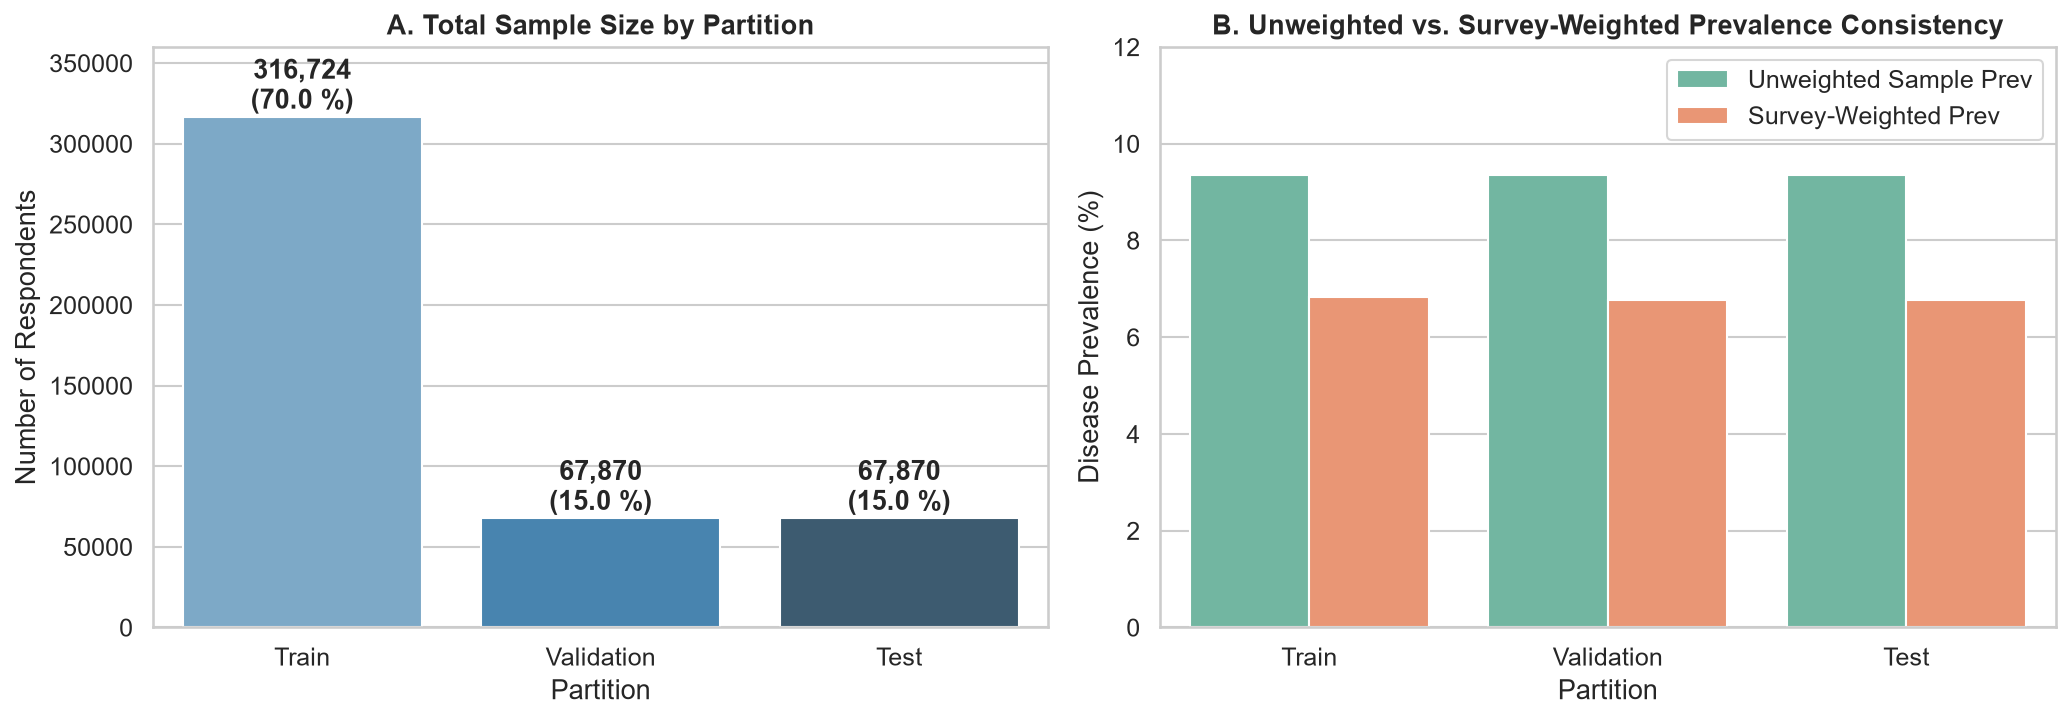

In [6]:
# Visual verification of class balance across partitions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_data = partition_summary_df[partition_summary_df["partition"] != "Full Eligible Cohort"].copy()

# Subplot A: Total sample size per partition
sns.barplot(data=plot_data, x="partition", y="total_records", hue="partition", legend=False, palette="Blues_d", ax=axes[0])
for i, row in plot_data.iterrows():
    axes[0].text(i, row["total_records"] + 5000, f"{row['total_records']:,}\n({row['pct_of_cohort']} %)", ha="center", weight="bold")
axes[0].set_title("A. Total Sample Size by Partition", weight="bold")
axes[0].set_xlabel("Partition")
axes[0].set_ylabel("Number of Respondents")
axes[0].set_ylim(0, 360000)

# Subplot B: Unweighted vs Survey-Weighted Prevalence
prev_melt = plot_data.melt(
    id_vars=["partition"],
    value_vars=["unweighted_prevalence_pct", "survey_weighted_prevalence_pct"],
    var_name="Prevalence Type",
    value_name="Prevalence (%)"
)
prev_melt["Prevalence Type"] = prev_melt["Prevalence Type"].map({
    "unweighted_prevalence_pct": "Unweighted Sample Prev",
    "survey_weighted_prevalence_pct": "Survey-Weighted Prev"
})
sns.barplot(data=prev_melt, x="partition", y="Prevalence (%)", hue="Prevalence Type", palette="Set2", ax=axes[1])
axes[1].set_title("B. Unweighted vs. Survey-Weighted Prevalence Consistency", weight="bold")
axes[1].set_xlabel("Partition")
axes[1].set_ylabel("Disease Prevalence (%)")
axes[1].set_ylim(0, 12)
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

## 5. Leakage-Safe Preprocessing Pipeline Construction

We construct a scikit-learn `ColumnTransformer`:
- **Numeric pipeline:** Median imputation (`SimpleImputer(strategy='median')`) followed by standard scaling (`StandardScaler()`).
- **Categorical pipeline:** Explicit sentinel missingness imputation (`SimpleImputer(strategy='constant', fill_value=-1.0)`) followed by one-hot encoding (`OneHotEncoder(handle_unknown='ignore')`). Preserves genuine missingness as an explicit, separate category (-1.0) guaranteed not to collide with non-negative valid BRFSS response codes.

**MANDATORY LEAKAGE ENFORCEMENT:**
The preprocessor is fitted **ONLY on `X_train`**. Validation and test partitions are transformed using the training parameters, preventing statistical data leakage across folds.


In [7]:
preprocessor = build_preprocessor_pipeline()
print("Fitting ColumnTransformer on X_train ONLY...")
preprocessor.fit(X_dict["train"])
print("ColumnTransformer fitted successfully.")

# Transform a sample of train and validation sets
train_sample_trans = preprocessor.transform(X_dict["train"].head(100))
val_sample_trans = preprocessor.transform(X_dict["validation"].head(100))

cat_ohe = preprocessor.named_transformers_["cat"].named_steps["onehot"]
num_feature_names = feature_config.NUMERIC_FEATURES
cat_feature_names = cat_ohe.get_feature_names_out(feature_config.CATEGORICAL_FEATURES)
all_transformed_feature_names = list(num_feature_names) + list(cat_feature_names)

print(f"Transformed input feature dimension: {len(all_transformed_feature_names)} columns (from 38 raw predictors).")
print(f"  Numeric feature count:     {len(num_feature_names)}")
print(f"  One-Hot categorical count: {len(cat_feature_names)}")

# Save fitted preprocessor artifact
MODELS_DIR.mkdir(parents=True, exist_ok=True)
preprocessor_artifact_path = MODELS_DIR / "preprocessor.joblib"
joblib.dump(preprocessor, preprocessor_artifact_path)
print(f"Saved fitted preprocessor to {preprocessor_artifact_path}")

Fitting ColumnTransformer on X_train ONLY...


ColumnTransformer fitted successfully.
Transformed input feature dimension: 190 columns (from 38 raw predictors).
  Numeric feature count:     4
  One-Hot categorical count: 186
Saved fitted preprocessor to C:\Users\Asus\Desktop\7 SEM\7-HA\CA-3\Project\models\preprocessor.joblib


## 6. Processed Dataset Serialization & Artifact Integrity Verification

All datasets are saved as gzip-compressed CSV files in `data/processed/`:
- `train_features.csv.gz`, `train_target.csv.gz`
- `validation_features.csv.gz`, `validation_target.csv.gz`
- `test_features.csv.gz`, `test_target.csv.gz`
- `cohort_metadata.csv.gz` (survey weights `_LLCPWT`, `_STSTR`, `_PSU`, `_STATE` with partition assignments)

We verify that all saved artifacts reload with 100% integrity.

In [8]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Verify files exist and can be reloaded
for part in ["train", "validation", "test"]:
    x_file = PROCESSED_DIR / f"{part}_features.csv.gz"
    y_file = PROCESSED_DIR / f"{part}_target.csv.gz"
    
    assert x_file.exists(), f"Missing artifact: {x_file}"
    assert y_file.exists(), f"Missing artifact: {y_file}"
    
    loaded_x = pd.read_csv(x_file, index_col=0, nrows=10)
    loaded_y = pd.read_csv(y_file, index_col=0, nrows=10)
    assert len(loaded_x) == 10 and len(loaded_y) == 10, "Reload row count error!"
    print(f"Verified {part} partition files exist and reload successfully.")

meta_file = PROCESSED_DIR / "cohort_metadata.csv.gz"
assert meta_file.exists(), f"Missing metadata: {meta_file}"
meta_sample = pd.read_csv(meta_file, index_col=0, nrows=10)
print(f"Verified cohort metadata exists ({meta_sample.shape[1]} columns: {list(meta_sample.columns)}).")
print("\nAll Milestone 5 artifacts verified. Ready for baseline model training in Milestone 6!")

Verified train partition files exist and reload successfully.
Verified validation partition files exist and reload successfully.
Verified test partition files exist and reload successfully.
Verified cohort metadata exists (8 columns: ['record_id', '_MICHD', 'target', '_LLCPWT', '_STSTR', '_PSU', '_STATE', 'partition']).

All Milestone 5 artifacts verified. Ready for baseline model training in Milestone 6!
